# SymPy でコードを自動生成する

SymPy は、式をいろいろな形で出力できます。LaTeX や MathML のような表示用の形式だけでなく、Python、C、Fortran のコードにも変換できます。シンボリックな式を、数値計算の関数に変えることもできます。

* `lambdify()` で式を Python の関数にする
* `autowrap()` で C の拡張モジュールにする
* `codegen()` で C のソースコードを書き出す

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
from sympy import *
import sympy

## `lambdify` で式を関数にする

`lambdify()` は、式を数値計算の関数に変えます。例として、`solve()` で 2 次方程式の解を記号のまま求めます。

In [2]:
a, b, c, x = symbols("a, b, c, x", real=True)
quadratic_roots = solve(a * x**2 + b * x + c, x)  # 2 次方程式の解
quadratic_roots

[(-b - sqrt(-4*a*c + b**2))/(2*a), (-b + sqrt(-4*a*c + b**2))/(2*a)]

`lambdify()` で式を関数にし、その関数を呼んで数値解を求めます。第 1 引数は、作る関数の引数にする記号のリスト、第 2 引数が返す式です。リストやタプルを渡せば、複数の式の値を一度に返せます。

In [3]:
roots_numpy = lambdify([a, b, c], quadratic_roots)  # 式を関数にする
roots_numpy(2, -3, 1)

[np.float64(0.5), np.float64(1.0)]

`modules` を指定すると、式の中で使う数学関数を、どのモジュールのものにするかを決められます。既定では次の順に探します。

* SciPy があれば `["scipy", "numpy"]`
* NumPy だけなら `["numpy"]`
* どちらもなければ `["math", "mpmath", "sympy"]`

つまり、使えるなら SymPy の関数を `scipy` や `numpy` の関数で置き換えます。NumPy が入っているので、`sqrt` は `numpy.sqrt()` になり、配列も引数にできます。次の例では、3 つの 2 次方程式を一度に解きます。

In [4]:
roots_numpy(np.array([2, 1, 0.5]), -3, 1)

[array([0.5       , 0.38196601, 0.35424869]),
 array([1.        , 2.61803399, 5.64575131])]

作られた関数のソースコードと、その中の `sqrt` が何を指すかを調べれば、`lambdify()` がどんな関数を作ったかが分かります。

In [5]:
import inspect

print(inspect.getsource(roots_numpy))  # 関数のソースコードを表示
print(
    roots_numpy.__globals__["sqrt"] is np.sqrt
)  # 関数内で使用される sqrt の参照を取得

def _lambdifygenerated(a, b, c):
    return [(1/2)*(-b - sqrt(-4*a*c + b**2))/a, (1/2)*(-b + sqrt(-4*a*c + b**2))/a]

True


`modules` に `cmath` を渡すと、`sqrt()` が複素数を返すようになります。

In [6]:
import cmath

roots_cmath = lambdify((a, b, c), quadratic_roots, modules=cmath)  # cmath の sqrt を使う
roots_cmath(2, 2, 1)

[(-0.5-0.5j), (-0.5+0.5j)]

ソースコードは `roots_numpy()` と同じで、`sqrt` が `cmath` のものになっています。

In [7]:
print(inspect.getsource(roots_cmath))
print(roots_cmath.__globals__["sqrt"].__module__)

def _lambdifygenerated(a, b, c):
    return [(1/2)*(-b - sqrt(-4*a*c + b**2))/a, (1/2)*(-b + sqrt(-4*a*c + b**2))/a]

cmath


ソースコードを見ると、同じ計算を 2 回しています。`cse=True` にすると、共通する部分式を探してローカル変数に入れ、計算の回数を減らします。

In [8]:
roots_cse = lambdify((a, b, c), quadratic_roots, cse=True)  # 共通部分式をまとめる
print(inspect.getsource(roots_cse))

def _lambdifygenerated(a, b, c):
    x0 = sqrt(-4*a*c + b**2)
    x1 = (1/2)/a
    return [x1*(-b - x0), x1*(-b + x0)]



`sqrt(-4*a*c + b**2)` が `x0` に、`(1/2)/a` が `x1` に入り、同じ計算が 1 回で済みます。

`modules` に辞書を渡すと、呼ぶ関数を自分で決められます。次のコードでは、`sqrt` として `my_sqrt` が使われます。呼ぶと `my_sqrt` が計算し、そのときにメッセージを出します。

`modules` はリストでもよく、前にあるものほど優先されます。

In [9]:
def my_sqrt(x):
    print(f"call my_sqrt with {x}")
    return x**0.5


roots_myfunc = lambdify(
    (a, b, c), quadratic_roots, modules=[{"sqrt": my_sqrt}, "numpy"], cse=True
)
roots_myfunc(2, -3, 1)

call my_sqrt with 1


[0.5, 1.0]

In [10]:
roots_myfunc.__globals__["sqrt"]

<function __main__.my_sqrt(x)>

`lambdify()` は、一部の関数を内部で特別に扱います。そのため、`modules` で置き換えられないことがあります。そのときは、式の `replace()` で関数を別のものに変えてから、コードを作ります。

次の例は、$\min (2 \sin(t), 1)$ のコードが配列を扱えるように、`Min()` を `numpy.amin()` に置き換えるものです。生成されたコードを見ると、`Min()` が `amin()` になっています。ただし `t` が配列だと、例外になります。

In [11]:
t = symbols("t", real=True)
expr = Min(2 * sin(t), 1)  # 配列を扱えない式

f1 = lambdify([t], expr, modules="numpy")
print(inspect.getsource(f1))

x = np.linspace(0, 2 * np.pi, 10)
try:
    f1(x)
except ValueError as ex:
    print(ex)

def _lambdifygenerated(t):
    return reduce(minimum, [1, 2*sin(t)])



NumPy の `minimum()` は ufunc なので、配列をそのまま扱えます。`Min()` を `minimum()` に変えるには、SymPy の関数 `minimum` を自分で定義し、`replace()` で `Min` をそれに置き換えます。

In [12]:
minimum = Function("minimum")
f2 = lambdify([t], expr.replace(Min, minimum), modules="numpy")
print(inspect.getsource(f2))
print(f2(x))

def _lambdifygenerated(t):
    return minimum(1, 2*sin(t))

[ 0.00000000e+00  1.00000000e+00  1.00000000e+00  1.00000000e+00
  6.84040287e-01 -6.84040287e-01 -1.73205081e+00 -1.96961551e+00
 -1.28557522e+00 -4.89858720e-16]


自分で定義した関数と、実際に計算する関数の名前が違うときは、`modules` の辞書で対応を指定します。生成されたコードは `myfunc()` を呼びますが、その環境では `myfunc` が `np.minimum()` です。

In [13]:
myfunc = Function("myfunc")
f2 = lambdify([t], expr.replace(Min, myfunc), modules=[{"myfunc": np.minimum}, "numpy"])
print(inspect.getsource(f2))
print(f2.__globals__["myfunc"])

def _lambdifygenerated(t):
    return myfunc(1, 2*sin(t))

<ufunc 'minimum'>


## スプラインのコード生成

スプラインは、滑らかな曲線を多項式のつなぎで表す方法で、補間や近似に使います。隣り合う点を滑らかにつなぎ、データ点を大きく外れないように調整します。

次のコードは、`UnivariateSpline` でデータを滑らかに近似します。`s=1` は平滑化の強さです。

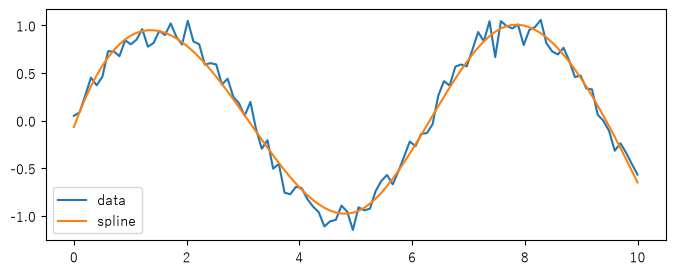

In [14]:
from scipy import interpolate

np.random.seed(42)
x_arr = np.linspace(0, 10, 100)
y_arr = np.sin(x_arr) + np.random.normal(scale=0.1, size=x_arr.shape[0])
spline = interpolate.UnivariateSpline(x_arr, y_arr, s=1)
plt.figure(figsize=(8, 3))
plt.plot(x_arr, y_arr, label="data")
plt.plot(x_arr, spline(x_arr), label="spline")
plt.legend();

`UnivariateSpline` の内部の属性 `_eval_args` に、スプラインを計算するのに必要な情報が入っています。`knots`、`coeffs`、`n` の 3 つです。

* `knots` は節点の位置です。ここで区間が分かれます。
* `coeffs` は各区間の多項式の係数です。
* `n` は節点の数です。

In [15]:
knots, coeffs, n = spline._eval_args
print(knots)
print(coeffs)
print(n)

[ 0.          0.          0.          0.          2.52525253  5.05050505
  7.57575758 10.         10.         10.         10.        ]
[-0.06742978  1.30989715  0.85005837 -2.17680281  2.11149148  0.3339333
 -0.65072061  0.          0.          0.          0.        ]
3


SymPy の `bspline_basis_set()` で、B スプラインの基底関数を式として計算できます。上の `knots` で基底関数を求め、グラフに描きます。

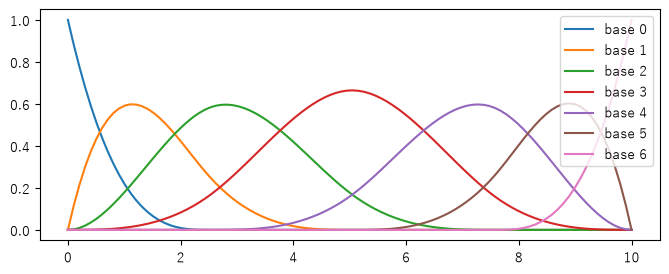

In [16]:
x = Symbol("x")
base_curves = bspline_basis_set(n, knots, x)  # B スプラインの基底

plt.figure(figsize=(8, 3))
for i, curve in enumerate(base_curves):
    plt.plot(x_arr, lambdify([x], curve)(x_arr), label=f"base {i}")
plt.legend();

各基底関数は `Piecewise()` の区分関数です。

In [17]:
base_curves[0]

Piecewise((-0.062099136*x**3 + 0.470448*x**2 - 1.188*x + 1.0, (x <= 2.52525252525253) & (x >= 0)), (0, True))

In [18]:
base_curves[1]

Piecewise((0.108673488*x**3 - 0.705672*x**2 + 1.188*x, (x <= 2.52525252525253) & (x >= 0)), (-0.015524784*x**3 + 0.235224*x**2 - 1.188*x + 2.0, (x >= 2.52525252525253) & (x <= 5.05050505050505)), (0, True))

基底関数に `coeffs` の係数を掛けて足すと、スプラインの式になります。次のコードで、`spline_expr` の値と `spline` の値が一致することが分かります。

In [19]:
spline_expr = sum([v * curve for v, curve in zip(coeffs, base_curves)])  # 係数を掛けて足す
spline_func = lambdify([x], spline_expr, cse=True)
np.allclose(spline(x_arr), spline_func(x_arr))

True

生成されたコードを見ると、NumPy の ufunc がたくさん使われています。

In [20]:
print(inspect.getsource(spline_func))

def _lambdifygenerated(x):
    x0 = x**2
    x1 = x**3
    x2 = logical_and.reduce((greater_equal(x, 7.57575757575758),less_equal(x, 10.0)))
    x3 = 1.188*x
    x4 = -0.470448*x0
    x5 = logical_and.reduce((less_equal(x, 2.52525252525253),greater_equal(x, 0)))
    x6 = -0.235224*x0
    x7 = logical_and.reduce((greater_equal(x, 2.52525252525253),less_equal(x, 5.05050505050505)))
    x8 = logical_and.reduce((greater_equal(x, 5.05050505050505),less_equal(x, 7.57575757575758)))
    x9 = 0.010349856*x1
    return -0.650720613486879*select([x2,True], [12.0849609375*x - 1.59521484375*x0 + 0.070189453125*x1 - 30.517578125,0], default=nan) - 0.0674297796339641*select([x5,True], [-0.062099136*x1 - x3 - x4 + 1.0,0], default=nan) + 1.30989714910869*select([x5,x7,True], [-0.705672*x0 + 0.108673488*x1 + x3,-0.015524784*x1 - x3 - x6 + 2.0,0], default=nan) + 0.33393329597181*select([x8,x2,True], [1.23698458975427*x - 0.244922948771345*x0 + 0.0161649146189088*x1 - 2.08246563931695,-22.4495388477457*x

`modules` を `"math"` にすると、生成されたコードは `if else` の並びになります。

In [21]:
spline_func_scalar = lambdify([x], spline_expr, modules="math", cse=True)
print(inspect.getsource(spline_func_scalar))

def _lambdifygenerated(x):
    x0 = x**2
    x1 = x**3
    x2 = (x >= 7.57575757575758) and (x <= 10.0)
    x3 = 1.188*x
    x4 = -0.470448*x0
    x5 = (x >= 0) and (x <= 2.52525252525253)
    x6 = -0.235224*x0
    x7 = (x >= 2.52525252525253) and (x <= 5.05050505050505)
    x8 = (x >= 5.05050505050505) and (x <= 7.57575757575758)
    x9 = 0.010349856*x1
    return -0.650720613486879*((12.0849609375*x - 1.59521484375*x0 + 0.070189453125*x1 - 30.517578125) if x2 else (0)) - 0.0674297796339641*((-0.062099136*x1 - x3 - x4 + 1.0) if x5 else (0)) + 1.30989714910869*((-0.705672*x0 + 0.108673488*x1 + x3) if x5 else (-0.015524784*x1 - x3 - x6 + 2.0) if x7 else (0)) + 0.33393329597181*((1.23698458975427*x - 0.244922948771345*x0 + 0.0161649146189088*x1 - 2.08246563931695) if x8 else (-22.4495388477457*x + 2.88169814497865*x0 - 0.121406413506091*x1 + 57.731987485683) if x2 else (0)) + 0.850058366700105*((-0.056924208*x1 - x6) if x5 else (1.782*x + 0.036224496*x1 + x4 - 1.5) if x7 else (-1.782*x +

[numba の `vectorize`](numba-vectorize) を使うと、スカラー用の関数を ufunc にコンパイルできます。コンパイルした `spline_func_scalar_jit` の値も、`spline` と一致します。

In [22]:
from numba import vectorize, float64

spline_func_scalar_jit = vectorize([float64(float64)])(spline_func_scalar)
np.allclose(spline(x_arr), spline_func_scalar_jit(x_arr))

True

時間を比べると、`spline_func_scalar_jit()` の方が約 3.5 倍速いことが分かります。

In [23]:
%timeit spline(x_arr)
%timeit spline_func_scalar_jit(x_arr)

15.4 μs ± 640 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


4.42 μs ± 483 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## `autowrap()` で式をコンパイルする

`lambdify()` は式を Python の関数にします。計算の多い式では、Python の関数にすると遅すぎます。そのときは `autowrap()` で式を C か Fortran のコードにし、Python から呼べる拡張モジュールにコンパイルします。`backend` で、コンパイルの方法を選びます。

* `'f2py'`：既定値。`f2py` で Fortran のプログラムを拡張モジュールにする。
* `'cython'`：Cython で C のプログラムを拡張モジュールにする。

ここでは `mingw32` を使うので、ビルド用のフォルダを作り、`setup.cfg` をそこにコピーします。

In [24]:
from pathlib import Path
import shutil

tmpdir = Path("./autowrap")
tmpdir.mkdir(parents=True, exist_ok=True)
shutil.copy("./setup.cfg", tmpdir);

2 つの解を `Matrix` にしてから、`autowrap()` で関数にします。この関数は実数の解だけを返すことに注意してください。

`autowrap()` には、一時ファイルを置く `tempdir` が必要です。ここにソースコードと拡張モジュールができます。`flags` で、コンパイルのコマンドにオプションを足せます。ここでは `-I` で NumPy のヘッダーファイルの場所を教えています。

In [25]:
from sympy.utilities.autowrap import autowrap

matrix_roots = Matrix(quadratic_roots)  # 2 つの解をまとめる
quadratic_roots_cython = autowrap(
    matrix_roots,
    args=[a, b, c],
    tempdir=tmpdir,
    backend="cython",
    flags=["-I" + np.get_include()],
)
quadratic_roots_cython(2, -3, 1)

array([[0.5],
       [1. ]])

`spline_expr` もコンパイルします。`-Ofast` を渡して、最適化したバイナリにします。

In [26]:
spline_cython = autowrap(
    spline_expr,
    args=[x],
    tempdir=tmpdir,
    backend="cython",
    flags=["-I" + np.get_include()],
    extra_compile_args=["-Ofast"],
)

In [27]:
np.allclose([spline_cython(v) for v in x_arr], spline(x_arr))

True

`spline_cython()` は 1 回に 1 つの値しか計算できません。Python のループで何度も呼ぶのは遅いので、`ufuncify()` で式を ufunc にします。

In [28]:
from sympy.utilities.autowrap import ufuncify

spline_cython_ufunc = ufuncify(
    [x],
    spline_expr,
    backend="cython",
    tempdir=tmpdir,
    flags=["-I" + np.get_include()],
    extra_compile_args=["-Ofast"],
)

まず、値が正しいかを確かめます。

In [29]:
np.allclose(spline_cython_ufunc(x_arr), spline(x_arr))

True

次に、計算の速さを測ります。Numba の版より速いことが分かります。

In [30]:
%timeit spline_cython_ufunc(x_arr)

1.55 μs ± 33.8 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


## codegen でソースコードを書く

`codegen()` は、式をソースコードに変えます。第 1 引数は (関数名, 式) のタプルか、そのリストです。`language` で言語を、`prefix` でファイル名を決めます。戻り値は 2 つのタプルで、ソースコードとヘッダーファイルの名前と中身です。式が `Matrix` なら、出力では配列に各要素を入れます。

In [31]:
from sympy.utilities.codegen import codegen

(c_name, c_code), (h_name, c_header) = codegen(
    [
        ("root0", quadratic_roots[0]),
        ("root1", quadratic_roots[1]),
        ("roots", matrix_roots),
    ],
    language="C",
    prefix="quadratic_roots",
    header=False,
)
print(h_name)
print("-" * 40)
print(c_header)
print()
print(c_name)
print("-" * 40)
print(c_code)

quadratic_roots.h
----------------------------------------

#ifndef PROJECT__QUADRATIC_ROOTS__H
#define PROJECT__QUADRATIC_ROOTS__H

double root0(double a, double b, double c);
double root1(double a, double b, double c);
void roots(double a, double b, double c, double *out_4276889304464714086);

#endif



quadratic_roots.c
----------------------------------------
#include "quadratic_roots.h"
#include <math.h>

double root0(double a, double b, double c) {

   double root0_result;
   root0_result = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
   return root0_result;

}

double root1(double a, double b, double c) {

   double root1_result;
   root1_result = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;
   return root1_result;

}

void roots(double a, double b, double c, double *out_4276889304464714086) {

   out_4276889304464714086[0] = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
   out_4276889304464714086[1] = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;

}



`ccode()` と `fcode()` で、式を C と Fortran の式として出力することもできます。

In [32]:
print(ccode(matrix_roots, assign_to="y"))

y[0] = (1.0/2.0)*(-b - sqrt(-4*a*c + pow(b, 2)))/a;
y[1] = (1.0/2.0)*(-b + sqrt(-4*a*c + pow(b, 2)))/a;


共通部分式をまとめたいときは、`CCodeGen` を直接使います。`cse=True` で作ると、cse を使ってコードが生成されます。

In [33]:
from sympy.utilities.codegen import CCodeGen

gen = CCodeGen("spline", cse=True)
r1 = gen.routine("spline_func", spline_expr, [x])
for filename, code in gen.write([r1], "spline"):
    print(filename)
    print(code)

spline.c
/******************************************************************************
 *                      Code generated with SymPy 1.14.0                      *
 *                                                                            *
 *              See http://www.sympy.org/ for more information.               *
 *                                                                            *
 *                       This file is part of 'spline'                        *
 ******************************************************************************/
#include "spline.h"
#include <math.h>

double spline_func(double x) {
   const double x0 = pow(x, 2);
   const double x1 = pow(x, 3);
   const double x2 = x >= 7.5757575757575752 && x <= 10.0;
   const double x3 = 1.1880000000000002*x;
   const double x4 = -0.47044800000000003*x0;
   const double x5 = x >= 0 && x <= 2.5252525252525251;
   const double x6 = -0.23522400000000002*x0;
   const double x7 = x >= 2.5252525252525251 &

## まとめ

* `lambdify()` で、式を数値計算の関数にできる。`modules` で使う関数を選ぶ。
* `cse=True` で、共通する部分式をまとめて計算を減らせる。
* 式が `Min()` のような特別な関数を含むときは、`replace()` で置き換えてからコードを作る。
* スプラインは `_eval_args` から節点と係数を取り出し、`bspline_basis_set()` で式にできる。
* `autowrap()` で C の拡張モジュールにコンパイルすると、`lambdify()` より速い。`ufuncify()` なら配列をそのまま渡せる。
* `codegen()` で C や Fortran のソースコードを書き出せる。